# From a trade book to netting-set exposure and XVA

Today's portfolio PV adds trade values. Future credit exposure first adds trade
values **within a legal netting set on each path**, then takes the positive or
negative part. Offsetting trades can therefore reduce exposure. This notebook
compares the same two swaps held together with those swaps held in separate
netting sets. [Setup](../README.md) · [Portfolio PV and risk](../sensitivity/portfolio_risk.ipynb).

`XvaConfig` controls the simulation. Each `NettingSet` carries its own `CsaTerms`
for collateral index/currency and credit/funding inputs. These terms are
separate from the contracts and from the model specification.

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import quantsupport as qs
from market_data import load_market, read_configuration

market = load_market()
ref = market.quotes.reference_date
config_spec = read_configuration(
    "cva",
    "xva.json",
)
config = qs.XvaConfig.from_dict(config_spec)
config_spec


{'model_configs': [{'market_index': 'SOFR',
   'lambda': 0.05,
   'parameter_source': {'Calibrated': {'source': {'Surface': {'market_index': 'SOFR'}},
     'calibration_basket': {'expiries': ['3M', '6M', '1Y', '2Y', '3Y'],
      'strike': 'Atm'}}}}],
 'n_paths': 1024,
 'seed': 42,
 'frequency': 'Quarterly'}

[xva.json](data/xva.json) configures a calibrated SOFR LGM model, 1024 paths,
seed 42, and quarterly exposure dates. The ATM calibration basket contains
3M, 6M, 1Y, 2Y, and 3Y expiries, covering this three-year portfolio. Longer
expiries in the shared surface have ATM forwards below its 3.5% minimum
strike; including those expiries would require additional market smile quotes,
not silent extrapolation. The engine generates future valuations directly.

[credit_curves.json](data/credit_curves.json) bootstraps CORPORATE-A survival
probabilities from the illustrative 1Y, 3Y, and 5Y CDS spreads in
[credit_quotes.json](data/credit_quotes.json). [csa_terms.json](data/csa_terms.json)
assigns this credit index, 40% recovery, and a dated funding-spread curve over
SOFR with spreads of 40, 50, and 60 bp. `credit_spread` is a fallback only;
`credit_index` takes precedence. These inputs are illustrative, not live data.

Variation margin is enabled with USD 1,000 receive/post thresholds and USD 500
minimum transfer amount. A threshold is the unsecured amount allowed; MTA is
the minimum absolute change in collateral balance that triggers a transfer.
Calls settle immediately on each simulation date, including the initial date,
and retained collateral accrues at the SOFR remuneration curve. Settlement
lag, margin period of risk, and initial margin are not modeled here.

The receive-fixed and pay-fixed positions share a maturity but differ in
notional. Each hypothetical client receives the same credit and funding terms
so the comparison isolates netting and collateral treatment.

In [5]:
def swap(identifier, notional, side):
    instrument = qs.Swap(
        identifier=identifier,
        start_date=ref,
        maturity_date=ref + "3Y",
        notional=notional,
        fixed_rate=0.045,
        currency=qs.Currency.USD,
        market_index=qs.MarketIndex.SOFR,
    )
    return qs.Trade(instrument, ref, side)


receive = swap("RECEIVE", 1_000_000, qs.Side.LongReceive)
pay = swap("PAY", 800_000, qs.Side.PayShort)
csa_spec = read_configuration("cva", "csa_terms.json")
csa = qs.CsaTerms.from_dict(csa_spec)
assert csa.credit_index == qs.MarketIndex.credit("CORPORATE-A")
assert csa.funding_spread_curve is not None
assert csa.variation_margin and csa.minimum_transfer_amount == 500.0


def run_exposure(netting_sets):
    with qs.PricingContext(
        quotes=market.quotes,
        curves=market.curves,
        credit_curves=market.credit_curves,
        csa_policy=market.csa_policy,
        volatility_surfaces=market.volatility_surfaces,
    ) as context:
        return context.run_xva(config, netting_sets=netting_sets)


netted = run_exposure([qs.NettingSet("ONE-CLIENT", [receive, pay], csa)])
separate = run_exposure([
    qs.NettingSet("CLIENT-A", [receive], csa),
    qs.NettingSet("CLIENT-B", [pay], csa),
])
credit_parameters = netted.sensitivities["parameter"].str.contains(
    "CVA.Cds_CORPORATE-A", regex=False
)
funding_parameters = netted.sensitivities["parameter"].str.contains(
    "FVA.funding_spread.", regex=False
)
assert credit_parameters.any() and funding_parameters.any()
assert np.isfinite(netted.xva_values["value"]).all()
netted.xva_values

,netting_set,measure,value
0,ONE-CLIENT,CVA,14.933653
1,ONE-CLIENT,FVA,3.486952


## Retrieve the three result views

`xva_values` is a table keyed by netting set and measure. `exposures` is a list
of profiles; select them by `netting_set`, rather than assuming list order.
`sensitivities` is the XVA parameter-risk table, separate from today's trade
PV sensitivities. CVA includes CDS-quote risk; FVA includes dated funding-spread
risk.

The reported EPE, ENE, and EE are **raw, pre-margin** netting-set exposures.
XVA aggregators instead consume each path's exposure after variation margin.
Consequently changing CSA thresholds can change XVA without changing these
raw profiles.

EPE is the expected positive value at each date, ENE is the expected negative
value **with a negative sign**, and EE is the signed mean, so `EE = EPE + ENE`.
EPE here is a date profile, not a single time-averaged scalar. The Python result
exposes these summaries, not the full pathwise NPV cube or PFE percentiles.

In [10]:
netted_profiles = {
    profile.netting_set: profile.to_dataframe().set_index("date")
    for profile in netted.exposures
}
separate_profiles = {
    profile.netting_set: profile.to_dataframe().set_index("date")
    for profile in separate.exposures
}
profile = netted_profiles["ONE-CLIENT"]
separate_total = separate_profiles["CLIENT-A"] + separate_profiles["CLIENT-B"]
assert np.allclose(
    profile["ee"],
    profile["epe"] + profile["ene"],
)
assert (profile["epe"] >= -1e-8).all() and (profile["ene"] <= 1e-8).all()
assert (profile["epe"] <= separate_total["epe"] + 1e-6).all()
profile.head(8)


,epe,ene,ee
date,,,
2026-02-24,1560.219484,0.000000,1560.219484
2026-05-24,2670.463071,-1102.076618,1568.386453
2026-08-24,3161.865586,-1317.550417,1844.315169
2026-11-24,3654.875072,-1824.342032,1830.533040
2027-02-24,3602.488961,-1488.065787,2114.423173
2027-05-24,3907.705731,-1808.613020,2099.092711
2027-08-24,3151.837395,-1343.436832,1808.400563
2027-11-24,3279.948042,-1500.874528,1779.073515


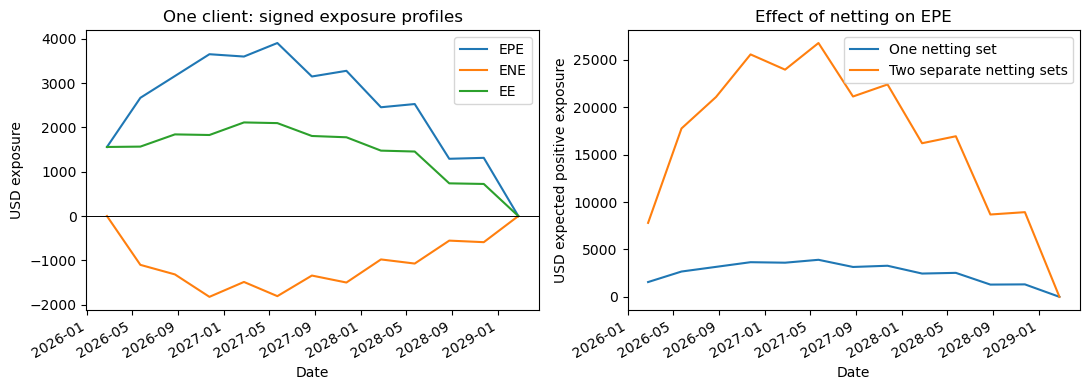

In [11]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4),
)
dates = pd.to_datetime(profile.index)
for measure in ["epe", "ene", "ee"]:
    axes[0].plot(
        dates,
        profile[measure],
        label=measure.upper(),
    )
axes[0].set(
    title="One client: signed exposure profiles",
    xlabel="Date",
    ylabel="USD exposure",
)
axes[0].axhline(
    0,
    color="black",
    linewidth=0.7,
)
axes[0].legend()
axes[1].plot(
    dates,
    profile["epe"],
    label="One netting set",
)
axes[1].plot(
    dates,
    separate_total["epe"],
    label="Two separate netting sets",
)
axes[1].set(
    title="Effect of netting on EPE",
    xlabel="Date",
    ylabel="USD expected positive exposure",
)
axes[1].legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


The swaps offset before the positive-part operation when they are in one
netting set. In separate sets, exposure to one client cannot be reduced by a
liability to another. Collateral balances and thresholds are applied separately
per legal set.

The table compares grouping with variation margin enabled, then disables
margin for the same netted portfolio while retaining identical credit,
funding, and model inputs. Preserve the engine's measure labels and sign
conventions in downstream reporting. CDS spreads, recovery, funding spreads,
and market quotes have different sensitivity units; thresholds and MTA are
amounts, not rates.

In [8]:
unmargined_csa = qs.CsaTerms.from_dict(dict(csa_spec, variation_margin=False))
unmargined = run_exposure([
    qs.NettingSet("ONE-CLIENT", [receive, pay], unmargined_csa),
])
comparison = pd.concat(
    {
        "one set, margin on": netted.xva_values.groupby("measure")["value"].sum(),
        "separate sets, margin on": separate.xva_values.groupby("measure")["value"].sum(),
        "one set, margin off": unmargined.xva_values.groupby("measure")["value"].sum(),
    },
    axis=1,
)
assert comparison.loc["CVA", "one set, margin on"] < comparison.loc[
    "CVA", "one set, margin off"
]
comparison

,"one set, margin on","separate sets, margin on","one set, margin off"
measure,,,
CVA,14.933653,24.859129,70.732865
FVA,3.486952,0.008304,20.850144


In [12]:
netted.sensitivities.sort_values(
    "value",
    key=lambda series: series.abs(),
    ascending=False,
).head(12)


,parameter,value
10,OIS_USD_SOFR_3Y,-1795.063566
8,OIS_USD_SOFR_2Y,817.163391
18,ONE-CLIENT.FVA.funding_spread.2027-02-24,374.603166
14,ONE-CLIENT.CVA.Cds_CORPORATE-A_USD_3Y,-283.167257
19,ONE-CLIENT.FVA.funding_spread.2029-02-24,204.096488
7,OIS_USD_SOFR_1Y,154.185460
17,ONE-CLIENT.FVA.funding_spread.2026-02-24,97.339413
13,ONE-CLIENT.CVA.Cds_CORPORATE-A_USD_1Y,-64.812584
16,ONE-CLIENT.CVA.recovery,-24.889421
2,CapletFloorlet_USD_SOFR_3M_3M_Absolute_0.035_S...,-8.880348


Increase path count and refine the exposure grid in the configuration to study
stability. Changing the seed helps reveal sampling variation. This example
isolates one-currency rate exposure; it does not establish the adequacy of a
model, calibration basket, or credit/funding assumption for another portfolio.